<a href="https://colab.research.google.com/github/freddyjosephthanikkal/Deep_Learning/blob/main/Heart_disease_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import tensorflow as tf
from tensorflow import keras
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("http://storage.googleapis.com/download.tensorflow.org/data/heart.csv")

In [3]:
df.shape

(303, 14)

In [4]:
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,1,145,233,1,2,150,0,2.3,3,0,fixed,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3,normal,1
2,67,1,4,120,229,0,2,129,1,2.6,2,2,reversible,0
3,37,1,3,130,250,0,0,187,0,3.5,3,0,normal,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0,normal,0


In [5]:
df.target.value_counts(normalize=True, dropna=False)

,proportion
target,
0,0.726073
1,0.273927


In [6]:
categorical_variables = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'ca', 'thal']
numericals = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak', 'slope']

In [7]:
df = pd.get_dummies(df, columns = categorical_variables)

In [8]:
test_df = df.sample(frac = 0.2, random_state = 42)
train_df = df.drop(test_df.index)

In [9]:
train_df.shape

(242, 30)

In [10]:
test_df.shape

(61, 30)

In [11]:
means = train_df[numericals].mean()
sd = train_df[numericals].std()

In [12]:
means

,0
age,54.268595
trestbps,131.995868
chol,246.512397
thalach,149.805785
oldpeak,1.032645
slope,1.590909


In [13]:
train_df[numericals] = (train_df[numericals] - means)/sd

In [14]:
test_df[numericals] = (test_df[numericals] - means)/sd

In [15]:
train_df.head()

,age,trestbps,chol,thalach,oldpeak,slope,target,sex_0,sex_1,cp_0,...,exang_1,ca_0,ca_1,ca_2,ca_3,thal_1,thal_2,thal_fixed,thal_normal,thal_reversible
0,0.963746,0.721939,-0.278690,0.008396,1.083461,2.226814,0,False,True,False,...,False,True,False,False,False,False,False,True,False,False
1,1.405254,1.554681,0.814423,-1.807247,0.399542,0.646494,1,False,True,False,...,True,False,False,False,True,False,False,False,True,False
2,1.405254,-0.665964,-0.361189,-0.899426,1.339930,0.646494,0,False,True,False,...,True,False,False,True,False,False,False,False,False,True
3,-1.906055,-0.110803,0.071931,1.607891,2.109339,2.226814,0,False,True,False,...,False,True,False,False,False,False,False,False,True,False
4,-1.464547,-0.110803,-0.876809,0.959447,0.314052,-0.933825,0,True,False,False,...,False,True,False,False,False,False,False,False,True,False


In [16]:
train = train_df.to_numpy()
test = test_df.to_numpy()

In [17]:
train_X = np.delete(train, 6, axis = 1)
test_X = np.delete(test, 6, axis = 1)

In [18]:
train_X.shape, test_X.shape

((242, 29), (61, 29))

In [19]:
train_y = train[:, 6]
test_y = test[:, 6]

In [20]:
train_y.shape, test_y.shape

((242,), (61,))

In [47]:
num_columns = train_X.shape[1]
input = keras.Input(shape = (num_columns,))
h = keras.layers.Dense(16,activation = "relu", name = "Hidden")(input)
output = keras.layers.Dense(1,activation = "sigmoid", name = "Output")(h)
model = keras.Model(input,output)

In [22]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 29)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Hidden (Dense)                  │ (None, 16)             │           480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output (Dense)                  │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 497 (1.94 KB)

 Trainable params: 497 (1.94 KB)

 Non-trainable params: 0 (0.00 B)

In [23]:
(29 + 1)* 16 + (16 + 1) * 1

497

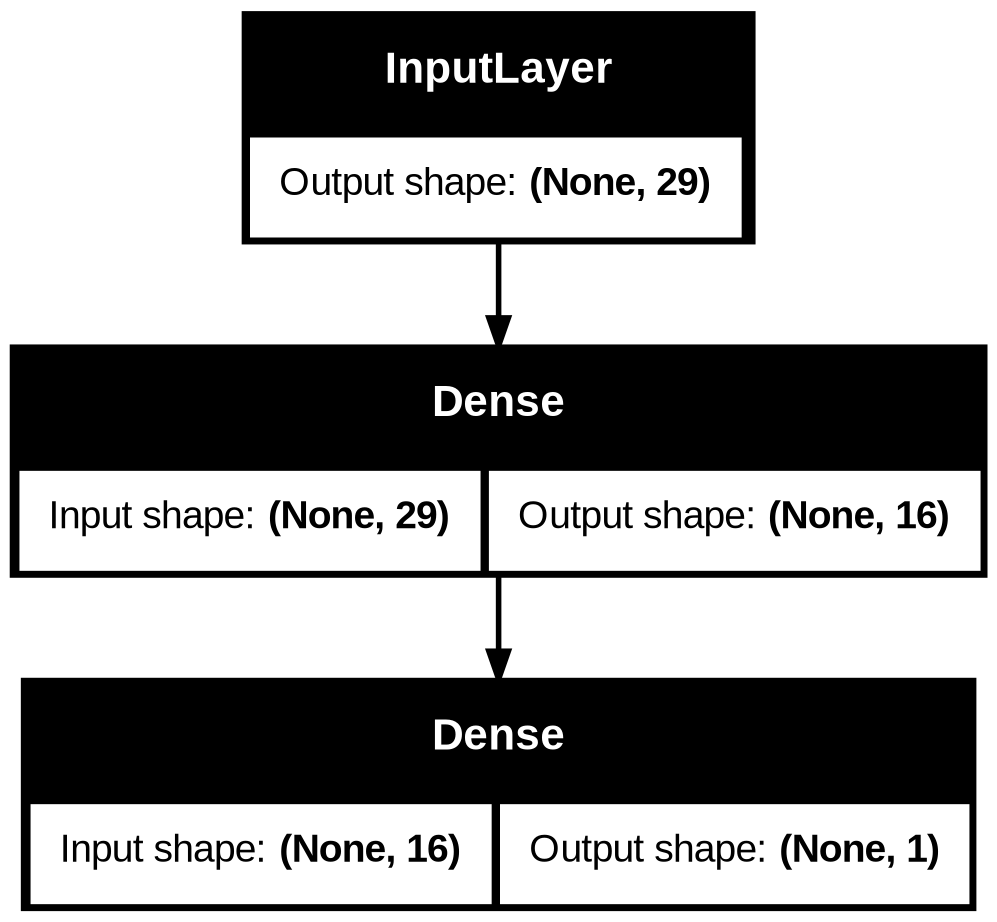

In [24]:
keras.utils.plot_model(model, show_shapes=True)

In [48]:
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

In [49]:
history = model.fit(train_X.astype(np.float32),              # the array with the input X columns
                    train_y.astype(np.float32),              # the array with the output y column
                    epochs=80,           # number of epochs to run
                    batch_size=32,        # number of samples (ie data points) per batch
                    verbose=1,            # verbosity during training
                    validation_split=0.3) # use 20% of the data for validation

Epoch 1/80
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 49ms/step - accuracy: 0.6213 - loss: 0.6710 - val_accuracy: 0.5479 - val_loss: 0.7341
Epoch 2/80
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.6450 - loss: 0.6328 - val_accuracy: 0.5890 - val_loss: 0.7136
Epoch 3/80
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.7101 - loss: 0.5986 - val_accuracy: 0.5890 - val_loss: 0.6955
Epoch 4/80
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.7337 - loss: 0.5683 - val_accuracy: 0.6027 - val_loss: 0.6786
Epoch 5/80
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.7456 - loss: 0.5414 - val_accuracy: 0.6027 - val_loss: 0.6639
Epoch 6/80
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.7515 - loss: 0.5185 - val_accuracy: 0.6301 - val_loss: 0.6503
Epoch 7/80
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.7870 - loss: 0.4975 - val_accuracy: 0.6301 - val_loss: 0.6381
Epoch 8/80
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.7988 - loss: 0.4781 - val_accuracy: 0.6301 - val_loss: 0.6269


In [27]:
history_dict = history.history
history_dict.keys()

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])

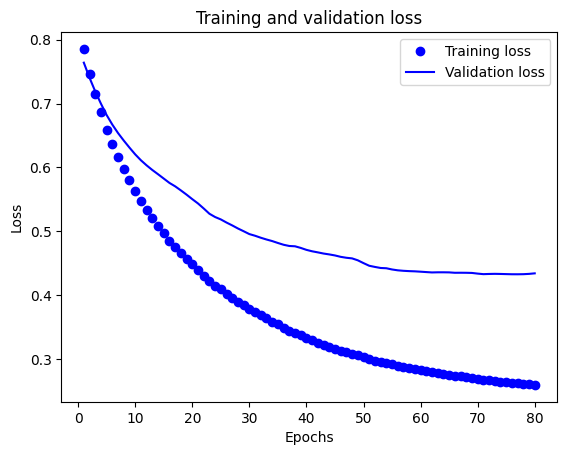

In [28]:
loss_values = history_dict["loss"]
val_loss_values = history_dict["val_loss"]
epochs = range(1, len(loss_values) + 1)
plt.plot(epochs, loss_values, "bo", label="Training loss")
plt.plot(epochs, val_loss_values, "b", label="Validation loss")
plt.title("Training and validation loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

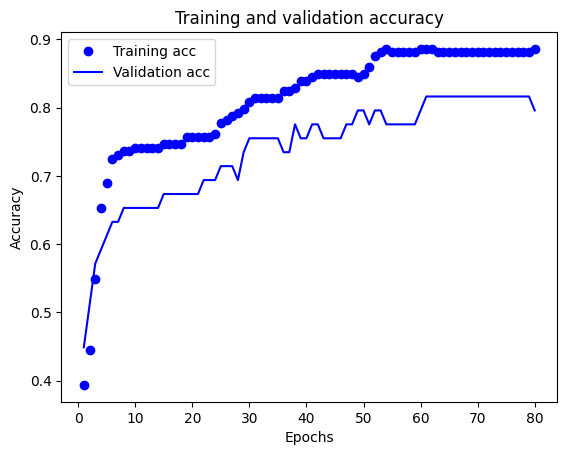

In [29]:
plt.clf()
acc = history_dict["accuracy"]
val_acc = history_dict["val_accuracy"]
plt.plot(epochs, acc, "bo", label="Training acc")
plt.plot(epochs, val_acc, "b", label="Validation acc")
plt.title("Training and validation accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

In [50]:
model.evaluate(test_X.astype(np.float32), test_y.astype(np.float32))

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.8689 - loss: 0.3295


[0.3294752240180969, 0.868852436542511]